# Data Exploration and Processing
## Shopify

### By: Makaled Consulting Group

In [1]:
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick
import numpy as np

In [2]:
df = pd.read_csv("Shopify_final(1).csv")

df.head()

,order_id,order_date,customer_id,product_id,product_category,product_price,discount_percent,quantity,customer_country,payment_method,...,revenue,profit,return_date,return_reason,refund_status,order_month,order_day,weekday_num,is_weekend,return_days
0,1,2023-04-13,14958,7824,Accessories,143.39,40,1,USA,Credit Card,...,86.0340,21.93700,NaN,NaN,NaN,2023-04,Thursday,3,False,NaN
1,2,2024-03-11,26825,5557,Sports,746.49,15,4,UAE,PayPal,...,2538.0660,1263.55300,NaN,NaN,NaN,2024-03,Monday,0,False,NaN
2,3,2025-05-10,37450,2225,Electronics,641.06,5,5,Canada,Apple Pay,...,3045.0350,1511.24750,NaN,NaN,NaN,2025-05,Saturday,5,True,NaN
3,4,2023-09-28,20691,7855,Footwear,512.39,0,3,UAE,Apple Pay,...,1537.1700,749.36500,NaN,NaN,NaN,2023-09,Thursday,3,False,NaN
4,5,2023-04-17,24631,7789,Sports,415.89,25,3,UAE,Debit Card,...,935.7525,442.93625,NaN,NaN,NaN,2023-04,Monday,0,False,NaN


### Univariate Analysis

Histograms

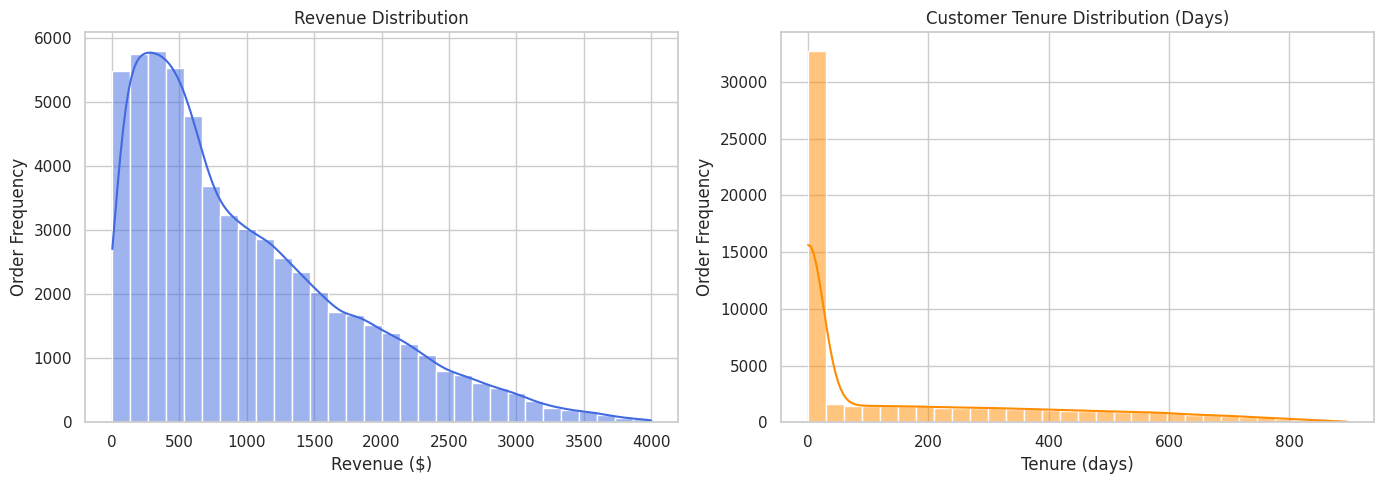

In [3]:
# Customer histograms over time and revenue distribution
df['order_date'] = pd.to_datetime(df['order_date'])
df['first_order_date'] = df.groupby('customer_id')['order_date'].transform('min')
df['customer_days'] = (df['order_date'] - df['first_order_date']).dt.days

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['revenue'], bins=30, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Revenue Distribution')
axes[0].set_xlabel('Revenue ($)')
axes[0].set_ylabel('Order Frequency')

sns.histplot(df['customer_days'], bins=30, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Customer Tenure Distribution (Days)')
axes[1].set_xlabel('Tenure (days)')
axes[1].set_ylabel('Order Frequency')

plt.tight_layout()
plt.show()

Where is the core of the business?

- In money: The volume is mainly located in the range of less than 800 USD per order, with a significant density between $150 and $500
- Distribution behavior: Shows positive skewness, with a large volume of low/medium ticket transactions and a long tail of higher value transactions reaching up to $4,000. Primary operations rely on purchases of lower unit value.

Average revenue per order: 994.10 USD
Median: 760 USD


In time:
Returns are distributed homogeneously across the entire common returns range (from 2 to 30 days)
Average: 16 days
Therefore, there is no critical peak of returns on any specific day

Boxplot

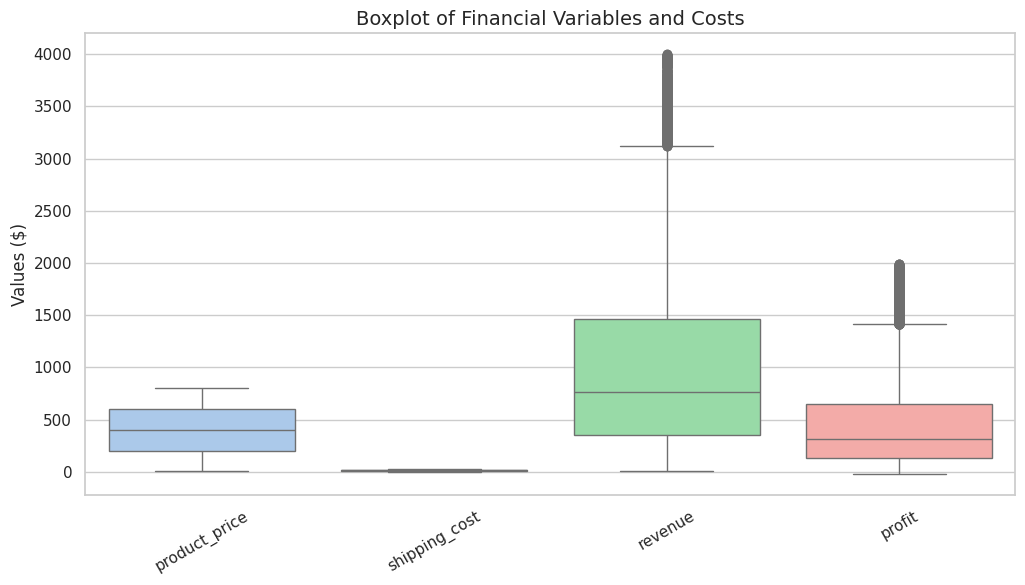

In [4]:
columnas_num = ['product_price', 'shipping_cost', 'revenue', 'profit']

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[columnas_num], palette='pastel')
plt.title('Boxplot of Financial Variables and Costs', fontsize=14)
plt.ylabel('Values ($)', fontsize=12)
plt.xticks(rotation=30)
plt.show()

Categorical Frequencies

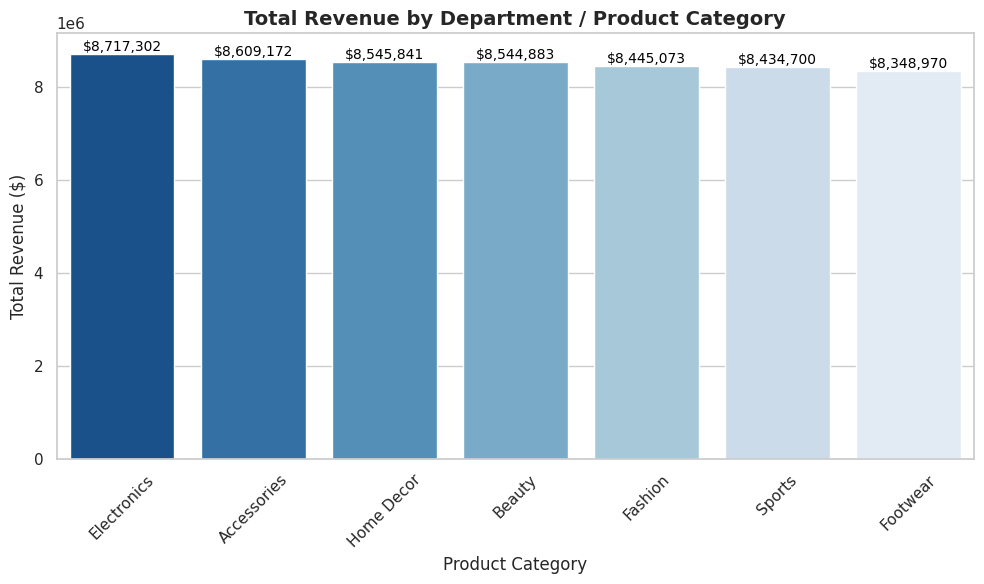

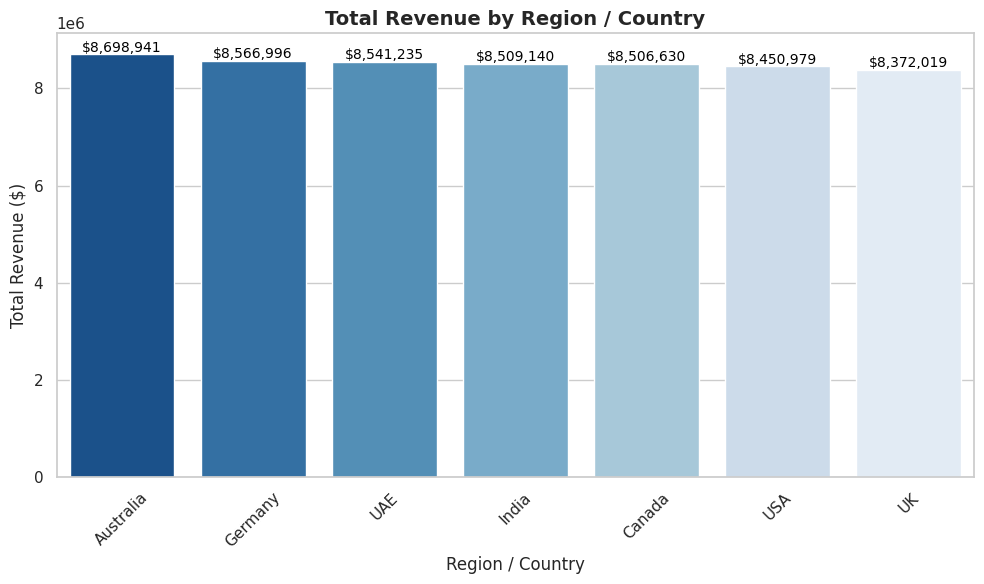

In [5]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
cat_rev = (
    df.groupby("product_category")["revenue"]
    .sum()
    .reset_index()
    .sort_values(by="revenue", ascending=False)
)

ax1 = sns.barplot(
    data=cat_rev,
    x="product_category",
    y="revenue",
    hue="product_category",
    palette="Blues_r",
    legend=False,
)

plt.title(
    "Total Revenue by Department / Product Category",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Total Revenue ($)", fontsize=12)
plt.xticks(rotation=45)

for p in ax1.patches:
    ax1.annotate(
        f"${p.get_height():,.0f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        fontsize=10,
        color="black",
        xytext=(0, 5),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
country_rev = (
    df.groupby("customer_country")["revenue"]
    .sum()
    .reset_index()
    .sort_values(by="revenue", ascending=False)
)

ax2 = sns.barplot(
    data=country_rev,
    x="customer_country",
    y="revenue",
    hue="customer_country",
    palette="Blues_r",
    legend=False,
)

plt.title("Total Revenue by Region / Country", fontsize=14, fontweight="bold")
plt.xlabel("Region / Country", fontsize=12)
plt.ylabel("Total Revenue ($)", fontsize=12)
plt.xticks(rotation=45)

for p in ax2.patches:
    ax2.annotate(
        f"${p.get_height():,.0f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        fontsize=10,
        color="black",
        xytext=(0, 5),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()

### Bivariate Analysis

Cross-analysis against target variable

Global return rate: 14.81%


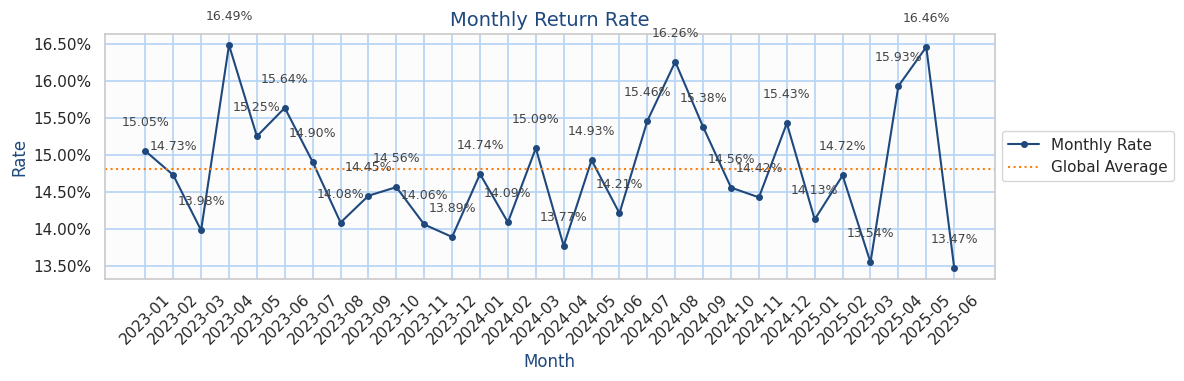

In [6]:
df_eda = df.copy()
df_eda["is_returned"] = df_eda["is_returned"].astype(int)
promedio = df_eda["is_returned"].mean()

print(f"Global return rate: {promedio:.2%}")

mensual = df_eda.groupby("order_month")["is_returned"].mean()

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(mensual.index, mensual.values, color="#1f497d", marker="o", markersize=4, label="Monthly Rate")
ax.axhline(promedio, color="#ff7f0e", ls=":", label="Global Average")

for x, y in zip(mensual.index, mensual.values):
    ax.text(x, y + 0.003, f"{y:.2%}", ha="center", va="bottom", fontsize=9, color="#444444")

ax.set_title("Monthly Return Rate", color="#1f497d", fontsize=14)
ax.set_ylabel("Rate", color="#1f497d")
ax.set_xlabel("Month", color="#1f497d")

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=2))
ax.grid(color="#b4d4f5", linestyle="-", linewidth=1.2)
ax.set_facecolor("#fcfcfc")

ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Verification of revenue loss due to returns

In [7]:
perdido = df_eda.loc[df_eda["is_returned"] == 1, "revenue"].sum()
total = df_eda["revenue"].sum()
print(f"Revenue in returned orders: ${perdido:,.0f} ({perdido/total:.2%} of total)")
print(f"Actual profit (excluding returned orders): ${df_eda.loc[df_eda['is_returned']==0, 'profit'].sum():,.0f}")

Revenue in returned orders: $8,782,563 (14.72% of total)
Actual profit (excluding returned orders): $24,739,828


Cross-tabulation of returns against all variables

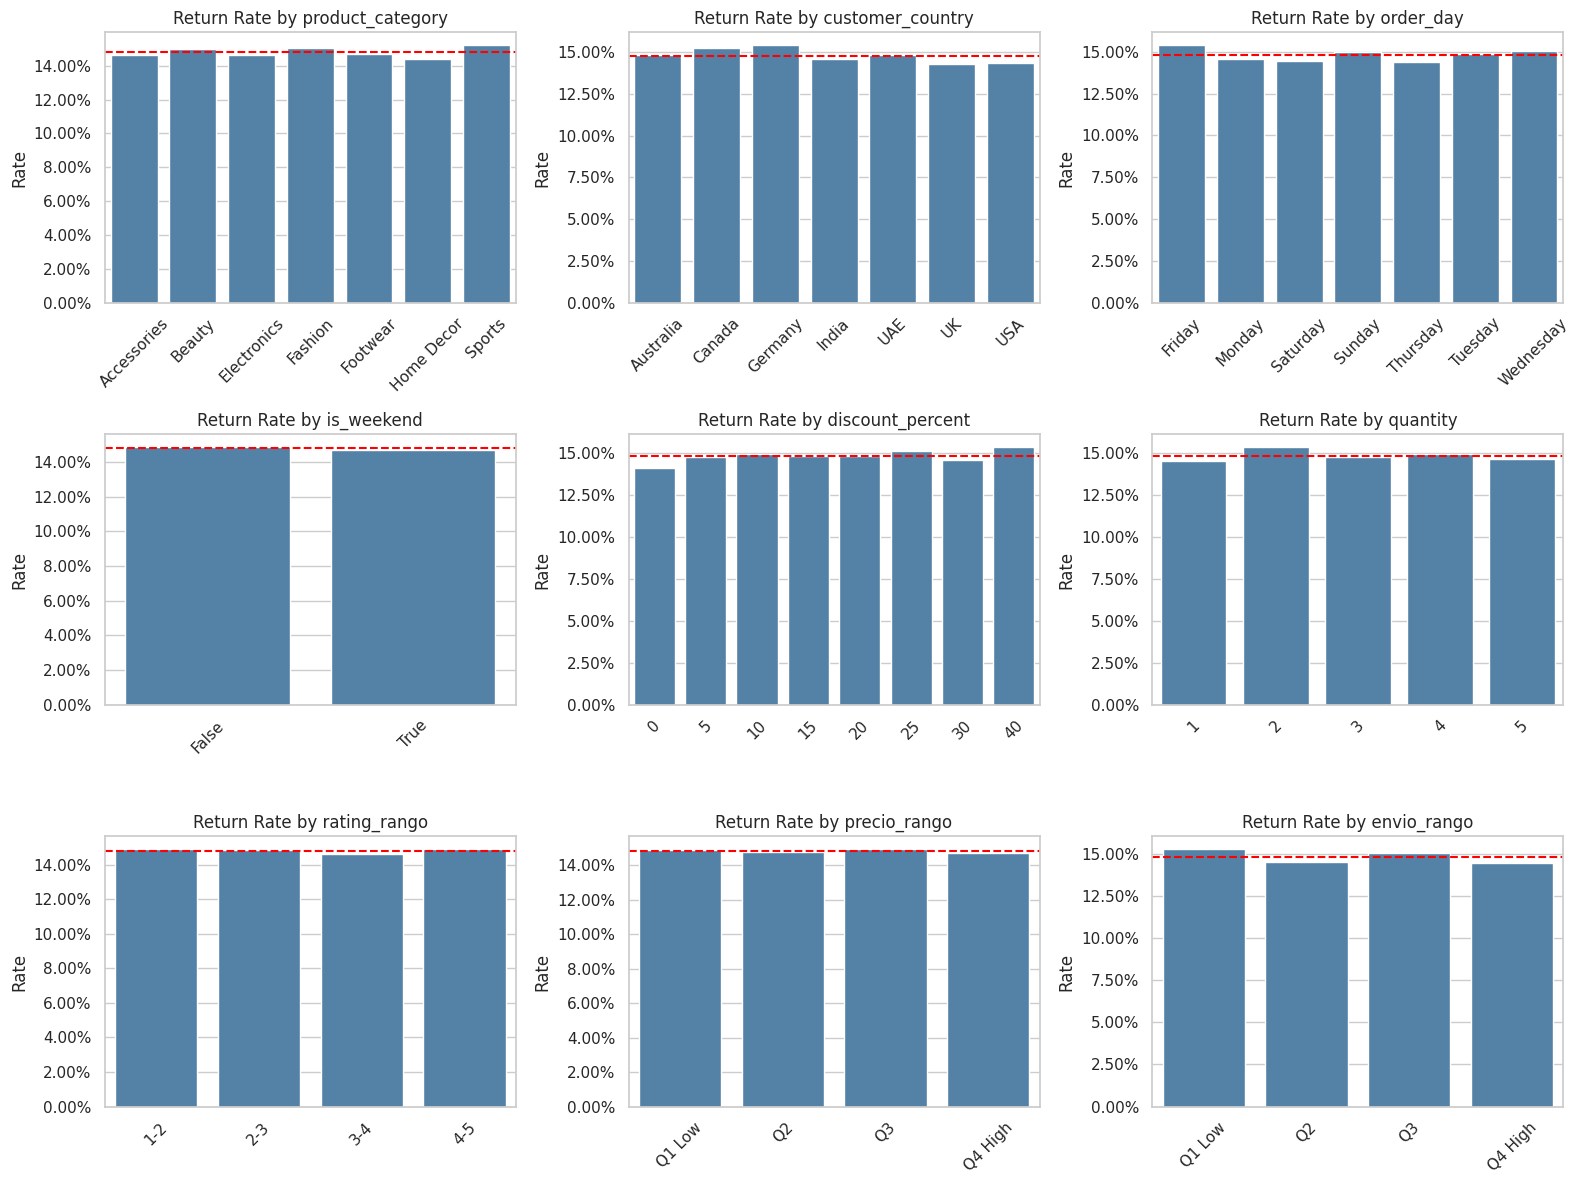

In [8]:
df_eda["rating_rango"] = pd.cut(df_eda["rating"], [0, 2, 3, 4, 5], labels=["1-2", "2-3", "3-4", "4-5"])
df_eda["precio_rango"] = pd.qcut(df_eda["product_price"], 4, labels=["Q1 Low", "Q2", "Q3", "Q4 High"])
df_eda["envio_rango"] = pd.qcut(df_eda["shipping_cost"], 4, labels=["Q1 Low", "Q2", "Q3", "Q4 High"])

variables = ["product_category", "customer_country", "order_day", "is_weekend",
             "discount_percent", "quantity", "rating_rango", "precio_rango", "envio_rango"]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, v in zip(axes.flat, variables):
    t = df_eda.groupby(v, observed=True)["is_returned"].mean()
    sns.barplot(x=t.index.astype(str), y=t.values, ax=ax, color="steelblue")
    ax.axhline(df_eda["is_returned"].mean(), color="red", ls="--")
    ax.set_title(f"Return Rate by {v}")
    ax.set_ylabel("Rate")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=2))

plt.tight_layout()
plt.show()

Scatter Plots

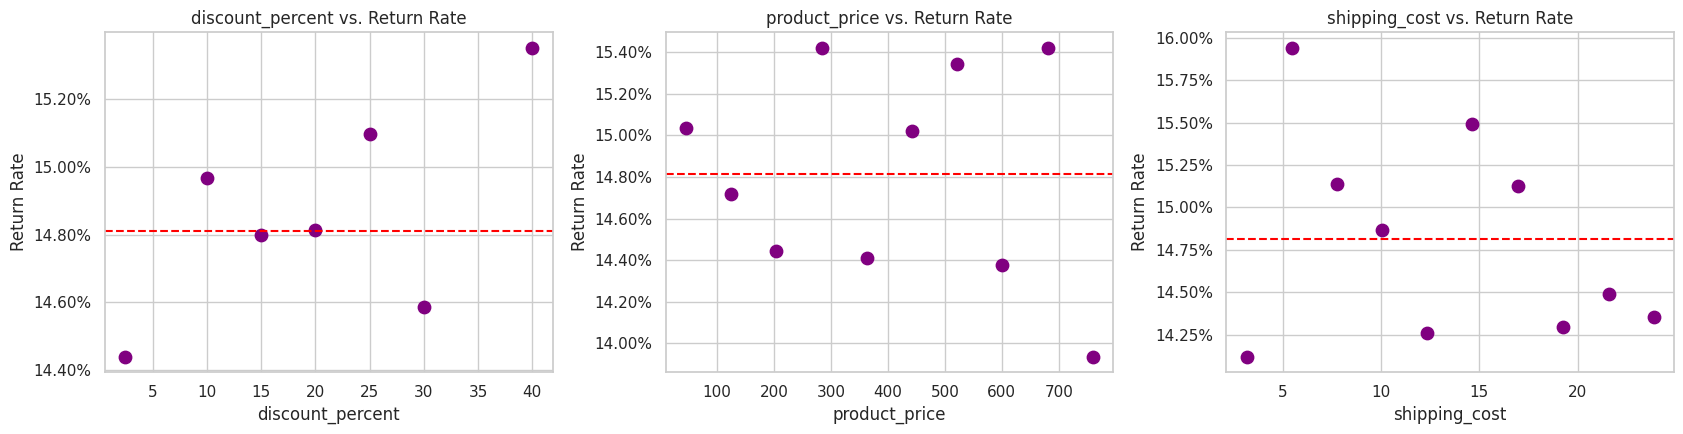

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, v in zip(axes, ["discount_percent", "product_price", "shipping_cost"]):
    bins = df_eda[v].nunique() if df_eda[v].nunique() <= 10 else 10
    g = df_eda.groupby(pd.cut(df_eda[v], bins), observed=True).agg(x=(v, "mean"), tasa=("is_returned", "mean"))

    ax.scatter(g["x"], g["tasa"], s=80, color="purple")
    ax.axhline(df_eda["is_returned"].mean(), color="red", ls="--")

    ax.set_xlabel(v)
    ax.set_ylabel("Return Rate")
    ax.set_title(f"{v} vs. Return Rate")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=2))

plt.tight_layout()
plt.show()

At first glance, there is no sustained trend in the scatter plots explaining returns. However, a few specific findings stand out:


* The highest return rate occurs with higher discount percentages (40%) and product prices exceeding 700 USD.
* Lower discounts, combined with lower shipping costs, account for few returns.


Business Focus: Return Days Histogram

Correlation Matrix

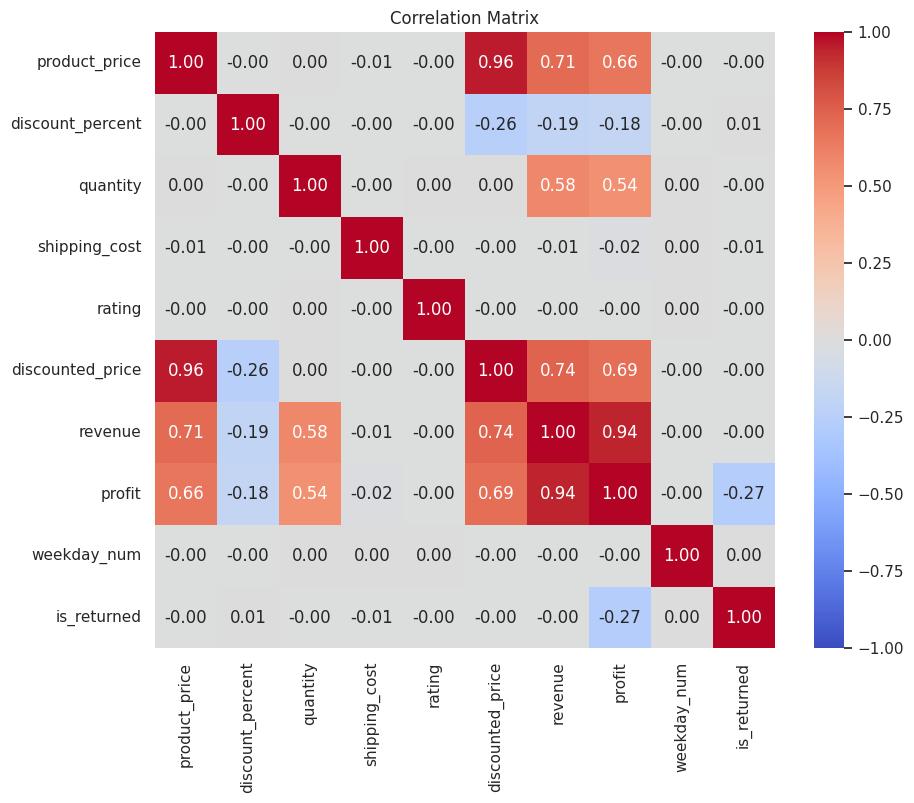

Correlation of each variable with is_returned:
profit             -0.2712
discount_percent    0.0065
shipping_cost      -0.0051
discounted_price   -0.0045
revenue            -0.0030
product_price      -0.0029
weekday_num         0.0015
quantity           -0.0007
rating             -0.0005
Name: is_returned, dtype: float64


In [10]:
cols = ["product_price", "discount_percent", "quantity", "shipping_cost", "rating",
        "discounted_price", "revenue", "profit", "weekday_num", "is_returned"]
corr = df_eda[cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Matrix"); plt.show()

print("Correlation of each variable with is_returned:")
print(corr["is_returned"].drop("is_returned").sort_values(key=abs, ascending=False).round(4))

**Key Findings**:



* Returns are not correlated with order rating.
* Discount percentage has a negative correlation with revenue and profit, rather than increasing them by incentivizing customers.
* Shipping cost has no correlation with item quantity, indicating standardized shipping pricing across orders.


### Time Series Analysis

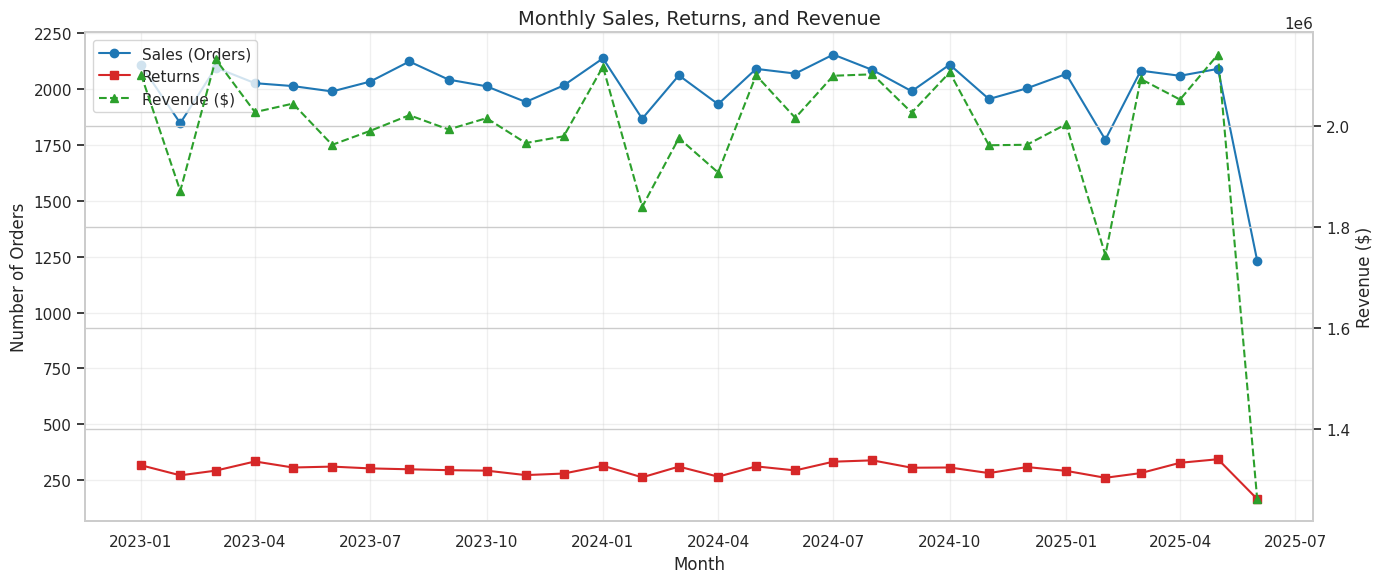

In [11]:
mensual = (
    df.groupby(df['order_date'].dt.to_period('M'))
    .agg(
        ventas=('order_id', 'size'),
        devoluciones=('is_returned', 'sum'),
        ingresos=('revenue', 'sum')
    )
)
mensual.index = mensual.index.to_timestamp()

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(mensual.index, mensual['ventas'], marker='o', label='Sales (Orders)', color='#1f77b4')
ax1.plot(mensual.index, mensual['devoluciones'], marker='s', label='Returns', color='#d62728')
ax1.set_xlabel('Month')
ax1.set_ylabel('Number of Orders')
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(mensual.index, mensual['ingresos'], marker='^', linestyle='--', label='Revenue ($)', color='#2ca02c')
ax2.set_ylabel('Revenue ($)')

lineas1, etiquetas1 = ax1.get_legend_handles_labels()
lineas2, etiquetas2 = ax2.get_legend_handles_labels()
ax1.legend(lineas1 + lineas2, etiquetas1 + etiquetas2, loc='upper left')

plt.title('Monthly Sales, Returns, and Revenue', fontsize=14)
plt.tight_layout()
plt.show()

Objective: Detect seasonality and audit data cutoff quality.

*Historical Line Chart:* Month-over-month sales, returns, and revenue. Sales and returns are measured in order volume (left axis) and revenue in currency (right axis).

*Visual Audit:* Checking if the 30-day moving average drops abruptly at the end of the series. Before concluding a business downturn, we verify whether the database is incomplete in the final quarter by comparing the maximum recorded date and last month's order volume against historical averages.

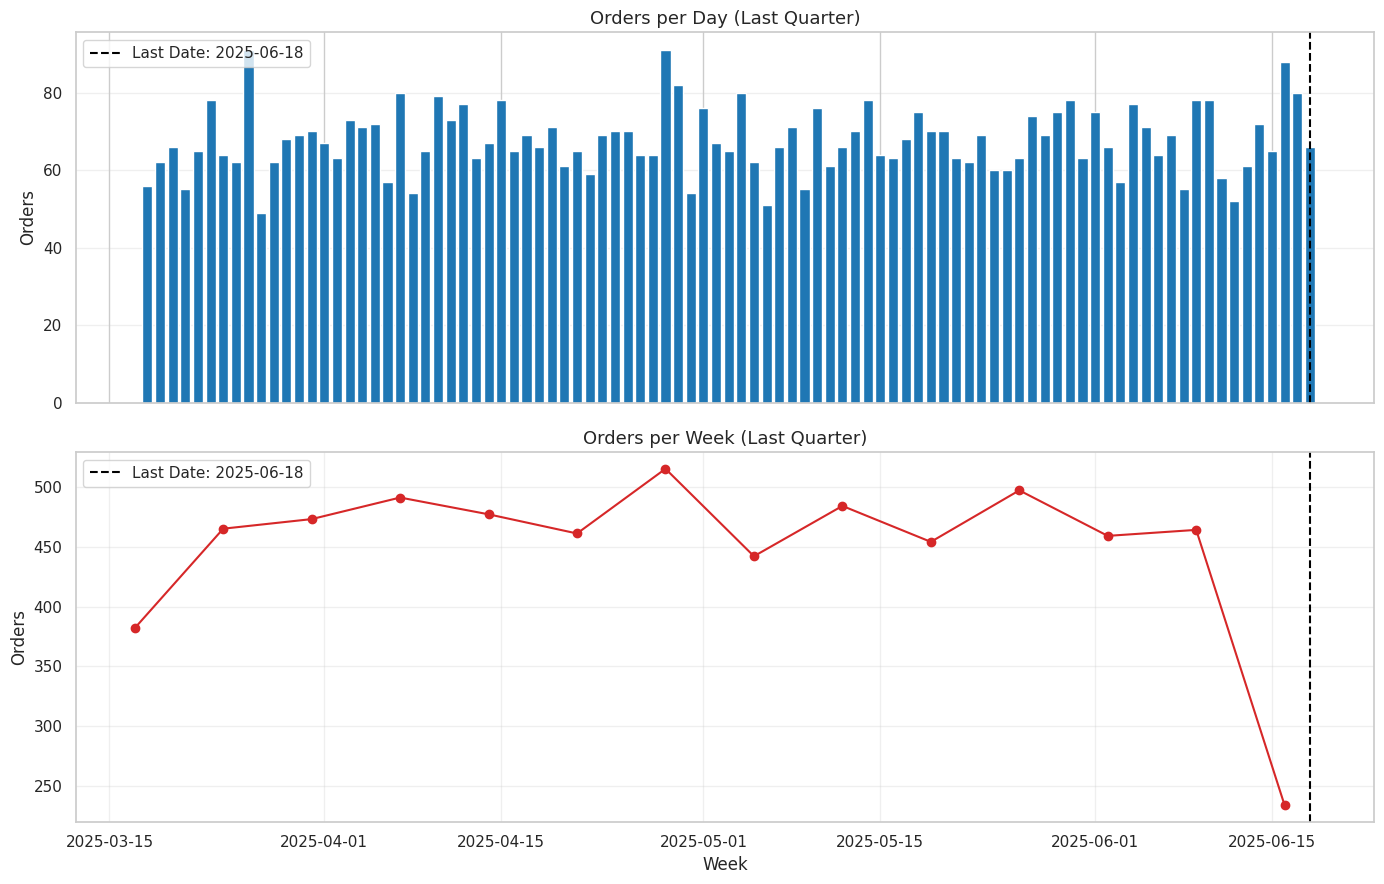

Last recorded date: 2025-06-18
Orders in last quarter: 6298
Days with records: 93


In [12]:
fecha_max = df['order_date'].max()
inicio_trim = fecha_max - pd.DateOffset(months=3)

# Only orders from the last quarter
ultimo_trim = df[df['order_date'] >= inicio_trim]

# Orders per day and per week
diario = ultimo_trim.groupby(ultimo_trim['order_date'].dt.normalize()).size()
semanal = ultimo_trim.groupby(ultimo_trim['order_date'].dt.to_period('W')).size()
semanal.index = semanal.index.to_timestamp()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Daily chart
ax1.bar(diario.index, diario.values, color='#1f77b4', width=0.8)
ax1.set_title('Orders per Day (Last Quarter)', fontsize=13)
ax1.set_ylabel('Orders')
ax1.grid(alpha=0.3, axis='y')

# Weekly chart
ax2.plot(semanal.index, semanal.values, marker='o', color='#d62728')
ax2.set_title('Orders per Week (Last Quarter)', fontsize=13)
ax2.set_ylabel('Orders')
ax2.set_xlabel('Week')
ax2.grid(alpha=0.3)

# Mark last recorded date
for ax in (ax1, ax2):
    ax.axvline(fecha_max, color='black', linestyle='--', label=f'Last Date: {fecha_max.date()}')
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

print(f"Last recorded date: {fecha_max.date()}")
print(f"Orders in last quarter: {len(ultimo_trim)}")
print(f"Days with records: {diario.size}")

### Database Integrity Audit

Before concluding that there was a decline in July 2025, we audit whether the database is complete.

**Audit Checks**
1. **Days without orders** within the date range. If heavily concentrated at the end, the extraction was cut off early.
2. **Gaps in `order_id`**. If unique IDs match expected sequential ranges, no internal rows are missing.
3. **Orders per month**, including the final month, to inspect if June 2025 is incomplete.
4. **Returns occurring after the last order date**. If present, return data was extracted later than order data.
5. **Daily orders in the final month**, to pinpoint exactly when recording stopped.

*Interpretation*
- If there are no missing days or sequence gaps in IDs, the database is intact during the recorded period.
- If orders end on June 18, 2025 while returns continue through July 17, the cutoff selectively affected order logging.
- If July does not appear in monthly counts, it is due to lack of post-cutoff order records rather than sales dropping to zero.

### Strategic Distillation

### North Star Metric: **Return Rate**

The Return Rate was selected as the primary indicator, as it measures the percentage of total placed orders that end up being returned. It is a critical business metric because returns directly impact revenue, profit margins, and overall customer satisfaction.

Based on the analysis, returned orders represent approximately 14.72% of total revenue, amounting to $8,782,563. This highlights a significant financial impact and underscores how reducing return volume directly strengthens bottom-line profitability.

### Supporting KPIs

- **Revenue Associated with Returned Orders:** Measures monetary revenue tied to orders that were subsequently returned.

- **Percentage of Revenue Impacted by Returns:** Complements the previous metric by showing what proportion of total gross revenue is lost to returns.

- **Real Profit from Non-Returned Orders:** Quantifies profit generated strictly from successfully completed orders, providing a true baseline of operating performance.

- **Average Return Window (Days):** Calculated via `return_days`, tracking the average timeframe elapsed between purchase and return initiation.

Return Days Statistics:
count    8887.000000
mean       15.958929
std         8.364919
min         2.000000
25%         9.000000
50%        16.000000
75%        23.000000
max        30.000000
Name: return_days, dtype: float64

 Average Return Days by Category:
product_category
Accessories    15.970681
Beauty         15.726920
Electronics    16.113312
Fashion        16.202012
Footwear       15.984739
Home Decor     16.130645
Sports         15.596762
Name: return_days, dtype: float64


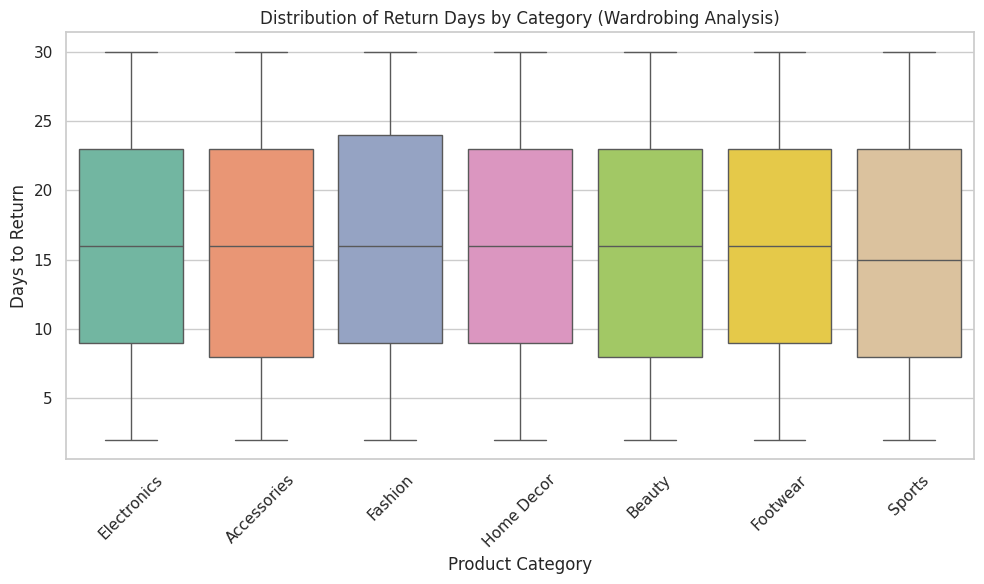

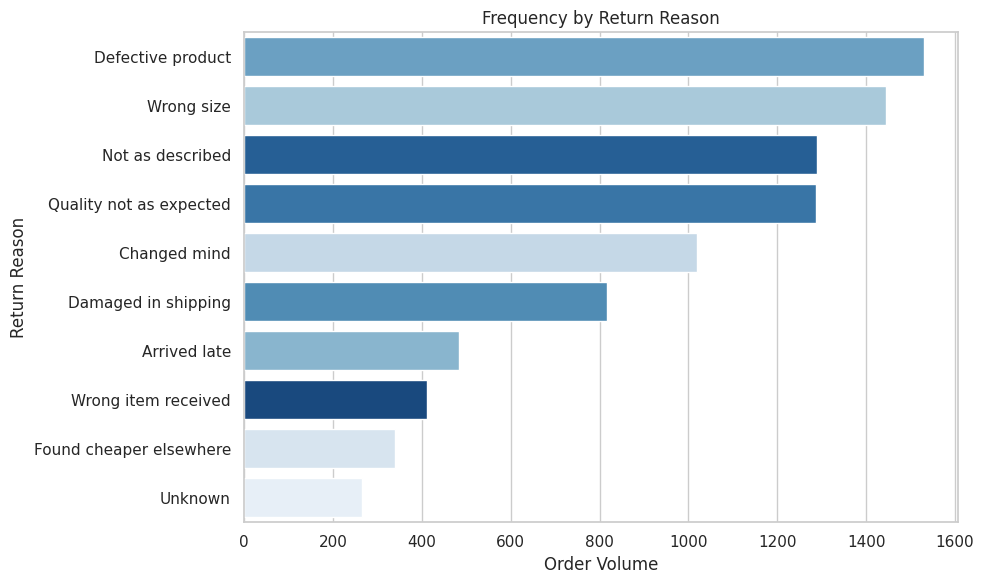

In [13]:
df_returns = df[df["return_days"].notnull()]

print("Return Days Statistics:")
print(df_returns["return_days"].describe())

print("\n Average Return Days by Category:")
print(df_returns.groupby("product_category")["return_days"].mean())

plt.figure(figsize=(10, 6))
sns.boxplot(
    x="product_category",
    y="return_days",
    data=df_returns,
    palette="Set2",
    hue="product_category",
    legend=False,
)
plt.title(
    "Distribution of Return Days by Category (Wardrobing Analysis)"
)
plt.xlabel("Product Category")
plt.ylabel("Days to Return")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.countplot(
    y="return_reason",
    data=df,
    order=df["return_reason"].value_counts().index,
    palette="Blues_r",
    hue="return_reason",
    legend=False,
)
plt.title("Frequency by Return Reason")
plt.xlabel("Order Volume")
plt.ylabel("Return Reason")
plt.tight_layout()
plt.savefig("return_reasons.png")
plt.show()

Establishing a critical analysis threshold is essential for identifying customer return behaviors and taking targeted operational measures—whether addressing wardrobing fraud, manufacturing defects, or courier logistics issues.

In our dataset, the "Fashion" category exhibits a slightly higher return volume relative to other departments. This suggests potential co-existence of legitimate logistics/sizing issues alongside wardrobing activity.

These findings validate the need to monitor return timeframes closely, refining return policies to safeguard overall margins without penalizing customers with genuine product issues.

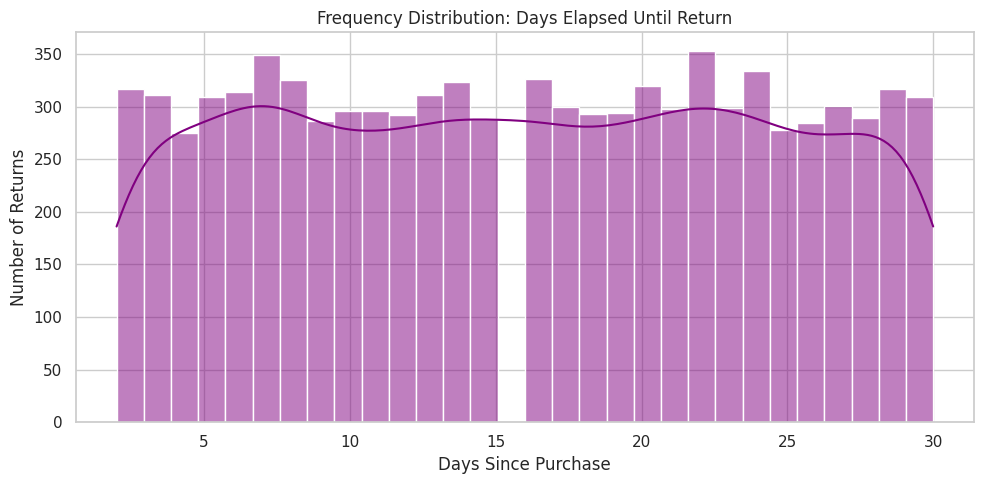

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(
    df["return_days"].dropna(), bins=30, kde=True, color="purple"
)
plt.title(
    "Frequency Distribution: Days Elapsed Until Return"
)
plt.xlabel("Days Since Purchase")
plt.ylabel("Number of Returns")
plt.tight_layout()
plt.show()

What does the histogram reveal?

The uniform distribution partially refutes the hypothesis of widespread wardrobing, as systemic wardrobing would produce a sharp, disproportionate spike near days 29–30.
Instead, this pattern supports the conclusion that returns stem from standard retail causes—such as sizing mismatches or manufacturing variances.

### Business Focus

In [15]:
d = df_eda.copy()
d["profit_dev"] = d["profit"].where(d["is_returned"] == 1, 0)
d["profit_ok"]  = d["profit"].where(d["is_returned"] == 0, 0)

cli = d.groupby("customer_id").agg(
    ordenes=("order_id", "count"),
    devoluciones=("is_returned", "sum"),
    profit_dev=("profit_dev", "sum"),
    profit_ok=("profit_ok", "sum"),
)
cli["impacto"] = cli["profit_ok"] - cli["profit_dev"]

print(cli["devoluciones"].value_counts().sort_index())
print(f"\nCustomers with net negative profit impact: {(cli['impacto'] < 0).sum():,}")

devoluciones
0    23180
1     7127
2      785
3       58
4        4
Name: count, dtype: int64

Customers with net negative profit impact: 3,169


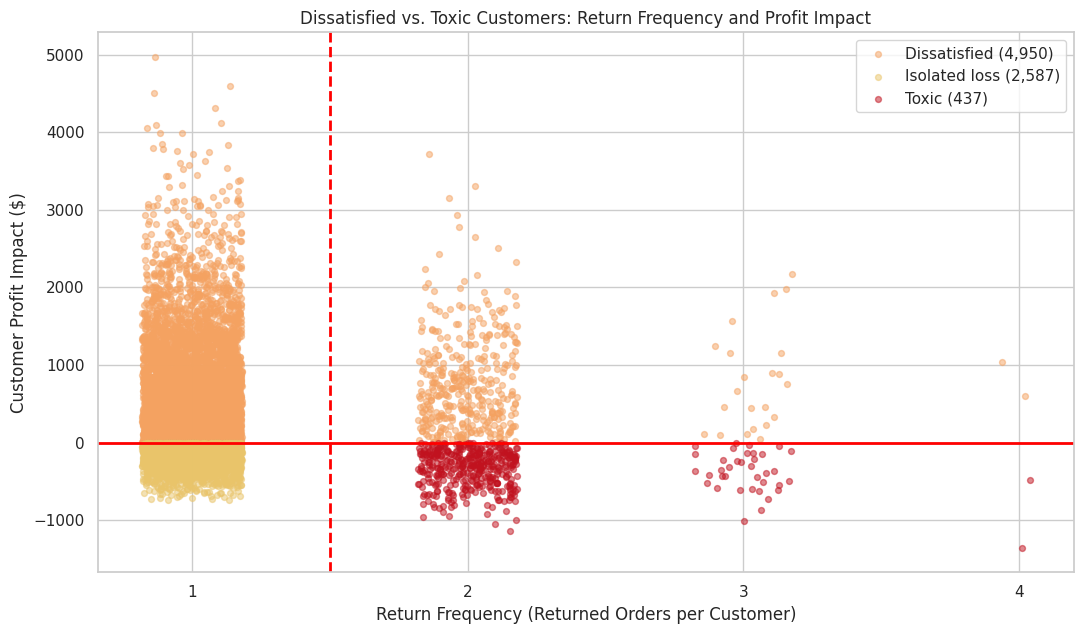

In [16]:
CORTE_FREC = 2   # minimum returns to classify as "recurrent"

def zona(r):
    if r["devoluciones"] == 0:
        return "No returns"
    if r["impacto"] >= 0:
        return "Dissatisfied"
    return "Toxic" if r["devoluciones"] >= CORTE_FREC else "Isolated loss"

cli["zona"] = cli.apply(zona, axis=1)

colores = {"Dissatisfied": "#f4a261", "Isolated loss": "#e9c46a", "Toxic": "#c1121f"}
dev = cli[cli["devoluciones"] > 0].copy()
rng = np.random.default_rng(42)
dev["x"] = dev["devoluciones"] + rng.uniform(-0.18, 0.18, len(dev))   # jitter

fig, ax = plt.subplots(figsize=(11, 6.5))
for z, c in colores.items():
    s = dev[dev["zona"] == z]
    ax.scatter(s["x"], s["impacto"], s=18, alpha=0.5, color=c, label=f"{z} ({len(s):,})")

ax.axhline(0, color="red", lw=2)
ax.axvline(CORTE_FREC - 0.5, color="red", lw=2, ls="--")
ax.set_xticks(sorted(dev["devoluciones"].unique()))
ax.set_xlabel("Return Frequency (Returned Orders per Customer)")
ax.set_ylabel("Customer Profit Impact ($)")
ax.set_title("Dissatisfied vs. Toxic Customers: Return Frequency and Profit Impact")
ax.legend(); plt.tight_layout(); plt.show()

In [17]:
resumen = cli.groupby("zona").agg(
    clientes=("ordenes", "size"),
    impacto_total=("impacto", "sum"),
    profit_devuelto=("profit_dev", "sum"),
)
resumen["% clientes"] = (resumen["clientes"] / len(cli) * 100).round(2)
print(resumen.round(0))

               clientes  impacto_total  profit_devuelto  % clientes
zona                                                               
Dissatisfied       4950      3940460.0         849111.0        16.0
Isolated loss      2587      -476048.0         587684.0         8.0
No returns        23180     19786463.0              0.0        74.0
Toxic               437      -148116.0         200273.0         1.0


# Analysis of Customer Return Frequency in Orders

Based on the findings from the visual distributions and collected customer return data, a small subset of customers (specifically 3,169) account for a net negative profit impact for the business.


Of these customers, approximately 1% (437) can be categorized as toxic customers (having more than 2 returns), representing the core group eroding profit margins.
However, looking closer at the recurring return segment, 9% of customers generate an unsustainable negative financial impact on operations, while 16% maintain a net positive return profile acceptable for business finances.


Furthermore, 2,587 customers (8%) yield isolated net losses due to circumstantial order factors (such as elevated logistics costs, steep discounts, or unfavorable cost structures rather than habitual abuse).


In conclusion, the empirical evidence urgently justifies implementing customer-level margin management policies—such as shipping cost adjustments, revised discount tiers, minimum order quantities (MOQ), or customer-adjusted profitability thresholds.
